# TapaCheck 2.0 — Transfer Learning + AutoGluon

**Start-up de Visión Artificial B2B · Entrega 4 · Visión Artificial (ITM)**

**El problema (el mismo de la Entrega 3).** En una embotelladora, la roscadora pone y aprieta la tapa de cada botella. A veces la tapa queda floja, ladeada sobre la rosca, o la botella sale sin tapa. Ese producto se derrama o pierde el gas, y el reclamo llega después desde el cliente. TapaCheck es una cámara fija después de la roscadora que revisa cada tapa.

**Qué cambia en esta entrega.** En la Entrega 3 TapaCheck usaba características hechas a mano (HOG, LBP y GLCM) y un SVM. Ahora las características salen de una **red convolucional preentrenada en ImageNet (Transfer Learning)**, con los pesos congelados, y la decisión la toma **AutoGluon**, que entrena y ensambla varios modelos tabulares:

1. **Selección de la red base:** se comparan EfficientNetB0, MobileNetV2, ResNet50 y DenseNet121 con los mismos datos.
2. **Extracción de embeddings con `tf.data`:** recorte fijo, redimensionamiento, normalización y carga por lotes. La red, sin su capa de clasificación, convierte cada foto en un vector de números.
3. **Tabla para AutoGluon:** un `DataFrame` con una fila por foto, las columnas `f_0, f_1, ...` y la etiqueta.
4. **Cabeza de decisión con AutoGluon** (`TabularPredictor`) y análisis de su *leaderboard*.
5. **Evaluación:** matriz de confusión, reporte de clasificación y curvas ROC-AUC, y **comparación con la Entrega 3** en las mismas 855 botellas de prueba.
6. **Comprobación en tiempo real:** la función `inspeccionar()` y la demo `demo_tiempo_real.py`, con cámara o con un flujo continuo de fotos.

**Dataset.** El mismo de la Entrega 3: [bottle_cap_sdp](https://universe.roboflow.com/bottlecapproject-dyaxy/bottle_cap_sdp) de Roboflow Universe (proyecto *bottlecapproject*, licencia CC BY 4.0), con fotos reales del cuello de botellas PET tomadas de lado. Ahora el sistema reconoce los **cuatro estados** de la tapa, y el veredicto del producto sigue siendo ROSCADA o MAL ROSCADA:

| Clase del dataset | Estado | Veredicto de TapaCheck |
|---|---|---|
| `good_cap` | Roscada | ROSCADA |
| `open_cap` | Floja | MAL ROSCADA |
| `misplaced_cap` | Ladeada | MAL ROSCADA |
| `no_cap` | Sin tapa | MAL ROSCADA |

**Cómo ejecutarlo.** El dataset va en `data/`, igual que en la Entrega 3 (versión de Roboflow con *Auto-Orient* y *Resize* a 640×640 *Stretch*, sin aumentación, exportada en formato YOLOv8). Se instalan las dependencias de `requirements.txt` y se ejecutan todas las celdas en orden. En un portátil sin GPU tarda unos 30 minutos la primera vez; los embeddings quedan guardados en `modelos/` y las siguientes ejecuciones son más rápidas.

## 1. Librerías y configuración

In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')   # oculta los mensajes informativos de TensorFlow
import glob
import json
import time
import shutil
import hashlib
import logging
import warnings
import cv2
import yaml
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from autogluon.tabular import TabularPredictor
from autogluon.tabular.configs.hyperparameter_configs import get_hyperparameter_config

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops   # solo para el sistema de la Entrega 3
from sklearn.exceptions import ConvergenceWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RUTA_DATOS = "data"
CARPETA_FIGURAS = "figuras"
CARPETA_MODELOS = "modelos"
MARGEN_ROI = 1.6               # mismo recorte fijo de la Entrega 3
TAMANO_CNN = (224, 224)        # tamaño de entrada con el que se entrenaron estas redes en ImageNet
LOTE = 32                      # fotos por lote en tf.data
TIEMPO_AUTOGLUON = 600         # segundos que AutoGluon puede usar para entrenar la cabeza de decisión
SEMILLA = 42

ESTADOS = ['Roscada', 'Floja', 'Ladeada', 'Sin tapa']
MAPA_ESTADOS = {'good_cap': 'Roscada', 'open_cap': 'Floja', 'misplaced_cap': 'Ladeada', 'no_cap': 'Sin tapa'}
CLASES = ['ROSCADA', 'MAL ROSCADA']   # veredicto del producto: todo estado distinto de 'Roscada' se aparta

keras.utils.set_random_seed(SEMILLA)
tf.get_logger().setLevel('ERROR')   # sin avisos internos de TensorFlow en las salidas
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)   # avisos de versiones futuras de sklearn dentro de AutoGluon
os.makedirs(CARPETA_FIGURAS, exist_ok=True)
os.makedirs(CARPETA_MODELOS, exist_ok=True)
plt.rcParams['figure.dpi'] = 110
print(f"TensorFlow {tf.__version__} · Keras {keras.__version__} · "
      f"dispositivos: {sorted({d.device_type for d in tf.config.list_physical_devices()})}")

TensorFlow 2.21.0 · Keras 3.12.4 · dispositivos: ['CPU']


## 2. Datos: las mismas fotos, la misma partición y el mismo recorte de la Entrega 3

Para que la comparación con la Entrega 3 sea justa, todo lo que no es el modelo queda igual:

- **Partición.** Se entrena con `train` (1.994 fotos) y se mide con `valid` + `test` (855 fotos que el modelo nunca ve). No hay fotos repetidas entre los dos grupos.
- **Recorte fijo (ROI).** La cámara está fija, así que la tapa siempre cae en el mismo cuadro. El cuadro se calibra una sola vez con las cajas anotadas de `train` (centro mediano de la tapa y lado de 1,6 veces su ancho mediano). Para clasificar, el sistema recibe **solo la foto**.
- **Lo único nuevo del recorte:** ahora se conserva el **color** y se lleva a **224×224 px**, porque las redes preentrenadas en ImageNet esperan imágenes RGB de ese tamaño.

In [2]:
extensiones = ('.jpg', '.jpeg', '.png', '.bmp')

def buscar_dataset(raiz):
    # Roboflow deja un data.yaml en la raíz del .zip descomprimido
    for actual, _, archivos in os.walk(raiz):
        if 'data.yaml' in archivos:
            return actual
    raise FileNotFoundError(f"No se encontró data.yaml dentro de '{raiz}/'. "
                            "Descomprima ahí el .zip de Roboflow en formato YOLOv8.")

def leer_nombres(carpeta):
    with open(os.path.join(carpeta, 'data.yaml'), encoding='utf-8') as f:
        nombres = yaml.safe_load(f)['names']
    return list(nombres.values()) if isinstance(nombres, dict) else list(nombres)

def leer_caja(linea):
    # Línea YOLO: clase cx cy w h (caja) o clase x1 y1 x2 y2 ... (polígono), todo de 0 a 1
    valores = linea.split()
    coords = np.array(valores[1:], dtype=float)
    if len(coords) == 4:
        cx, cy, w, h = coords
    else:
        xs, ys = coords[0::2], coords[1::2]
        cx, cy, w, h = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2, xs.max() - xs.min(), ys.max() - ys.min()
    return int(valores[0]), cx, cy, w, h

def leer_etiquetas(carpeta_split, nombres):
    # Una fila por foto: ruta, clase del dataset, estado y caja anotada (la caja solo calibra el recorte fijo)
    filas = []
    for ruta in sorted(glob.glob(os.path.join(carpeta_split, 'images', '*'))):
        if not ruta.lower().endswith(extensiones):
            continue
        ruta_txt = os.path.join(carpeta_split, 'labels', os.path.splitext(os.path.basename(ruta))[0] + '.txt')
        if not os.path.exists(ruta_txt):
            continue
        with open(ruta_txt) as f:
            cajas = [leer_caja(l) for l in f.read().splitlines() if l.strip()]
        if len(cajas) != 1 or nombres[cajas[0][0]] not in MAPA_ESTADOS:
            continue
        clase, cx, cy, w, h = cajas[0]
        filas.append({'ruta': ruta, 'tipo': nombres[clase], 'estado': MAPA_ESTADOS[nombres[clase]],
                      'cx': cx, 'cy': cy, 'w': w, 'h': h})
    return pd.DataFrame(filas)

carpeta = buscar_dataset(RUTA_DATOS)
nombres = leer_nombres(carpeta)
info_train = leer_etiquetas(os.path.join(carpeta, 'train'), nombres)
info_test = pd.concat([leer_etiquetas(os.path.join(carpeta, s), nombres) for s in ['valid', 'test']], ignore_index=True)

# Calibración del recorte fijo, una sola vez y solo con train (como al instalar la cámara)
ROI = {'cx': float(info_train['cx'].median()), 'cy': float(info_train['cy'].median()),
       'lado': float(MARGEN_ROI * info_train['w'].median())}
print(f"Recorte fijo: centro ({ROI['cx']:.3f}, {ROI['cy']:.3f}) y lado {ROI['lado']:.3f} del ancho de la foto")

y_estado_train = info_train['estado'].map(ESTADOS.index).to_numpy()
y_estado_test = info_test['estado'].map(ESTADOS.index).to_numpy()
y_train = (y_estado_train != 0).astype(int)   # 1 = MAL ROSCADA
y_test = (y_estado_test != 0).astype(int)

conteo = pd.DataFrame({'Train': info_train['estado'].value_counts(), 'Test': info_test['estado'].value_counts()})
conteo = conteo.reindex(ESTADOS).fillna(0).astype(int)
conteo.index = [f"{e} -> {CLASES[int(e != 'Roscada')]}" for e in conteo.index]
conteo.loc['Total'] = conteo.sum()
display(conteo)

def foto_original(ruta):
    # Roboflow nombra cada copia <foto>_jpg.rf.<código>.jpg: lo anterior a '.rf.' identifica la foto original
    return os.path.basename(ruta).split('.rf.')[0]

repetidas = set(info_train['ruta'].map(foto_original)) & set(info_test['ruta'].map(foto_original))
print(f"Fotos repetidas entre train y test: {len(repetidas)}")

Recorte fijo: centro (0.513, 0.506) y lado 0.604 del ancho de la foto


,Train,Test
Roscada -> ROSCADA,1414,606
Floja -> MAL ROSCADA,217,94
Ladeada -> MAL ROSCADA,174,74
Sin tapa -> MAL ROSCADA,189,81
Total,1994,855


Fotos repetidas entre train y test: 0


## 3. Flujo de procesamiento con `tf.data`

Cada foto recorre el mismo camino, escrito con `tf.data.Dataset` para que TensorFlow lea, prepare y entregue las imágenes por lotes mientras la red trabaja:

1. **`from_tensor_slices((rutas, etiquetas))`**: una entrada por foto, con su ruta y su estado (0 a 3).
2. **`map(cargar_y_recortar)`**: lee el archivo, lo decodifica en RGB, aplica el **recorte fijo** de la cámara y lo **redimensiona** a 224×224 con promedio de áreas (el equivalente de `INTER_AREA`). Si el cuadro se saliera de la foto, se rellena en espejo.
3. **`map(preprocess_input)`**: la **normalización** que espera cada red. ResNet50 resta la media de ImageNet por canal; MobileNetV2 lleva los píxeles a [-1, 1]; DenseNet121 los escala a [0, 1] y los estandariza. EfficientNetB0 trae la normalización dentro de la propia red, así que recibe los píxeles de 0 a 255.
4. **`batch(32)` y `prefetch(AUTOTUNE)`**: **carga por lotes** de 32 fotos, preparando el siguiente lote mientras se procesa el actual.

Los `map` se ejecutan en paralelo (`num_parallel_calls=AUTOTUNE`) pero con `deterministic=True`, así que **el orden de salida es el mismo orden de las rutas**. Eso es lo que garantiza que cada vector de características quede en la fila de su etiqueta.

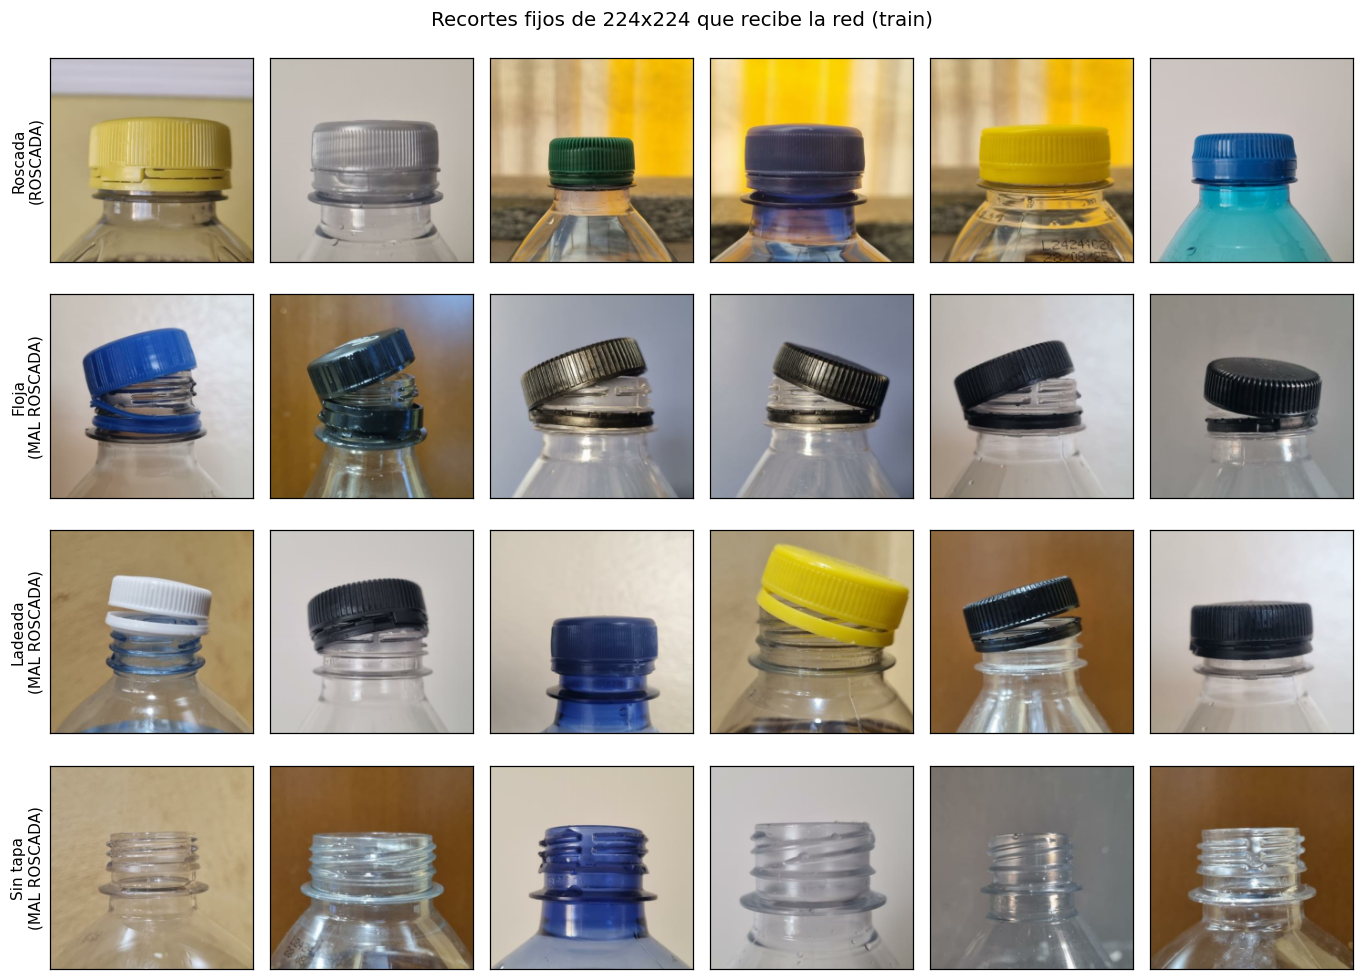

In [3]:
def cargar_y_recortar(ruta):
    # 1. Leer y decodificar la foto (RGB, uint8)
    img = tf.io.decode_image(tf.io.read_file(ruta), channels=3, expand_animations=False)
    alto, ancho = tf.shape(img)[0], tf.shape(img)[1]
    # 2. Recorte fijo de la cámara, el mismo cuadrado de la Entrega 3 (en fracciones de la foto)
    ancho_f = tf.cast(ancho, tf.float32)
    lado = tf.cast(tf.round(ROI['lado'] * ancho_f), tf.int32)
    mitad = tf.cast(lado, tf.float32) / 2
    x0 = tf.cast(tf.round(ROI['cx'] * ancho_f - mitad), tf.int32)
    y0 = tf.cast(tf.round(ROI['cy'] * tf.cast(alto, tf.float32) - mitad), tf.int32)
    borde = tf.maximum(0, tf.reduce_max(tf.stack([-x0, -y0, x0 + lado - ancho, y0 + lado - alto])))
    img = tf.pad(img, [[borde, borde], [borde, borde], [0, 0]], mode='SYMMETRIC')
    recorte = tf.image.crop_to_bounding_box(img, y0 + borde, x0 + borde, lado, lado)
    # 3. Redimensionar a 224x224 con promedio de áreas: queda en float32 de 0 a 255
    return tf.image.resize(recorte, TAMANO_CNN, method='area')

def crear_dataset(rutas, etiquetas, preprocesar):
    def leer(ruta, etiqueta):
        return cargar_y_recortar(ruta), etiqueta
    def normalizar(imagen, etiqueta):
        return preprocesar(imagen), etiqueta
    ds = tf.data.Dataset.from_tensor_slices((list(rutas), list(etiquetas)))                # 1. una entrada por foto
    ds = ds.map(leer, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)        # 2. leer, recortar, redimensionar
    ds = ds.map(normalizar, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)  # 3. normalización de la red
    return ds.batch(LOTE).prefetch(tf.data.AUTOTUNE)                                  # 4. lotes de 32

# Así ve la red cada tapa: recortes de 224x224 en color, antes de la normalización
fig, axes = plt.subplots(len(ESTADOS), 6, figsize=(12.5, 2.3 * len(ESTADOS)))
rng = np.random.default_rng(SEMILLA)
for fila, estado in enumerate(ESTADOS):
    idx = rng.choice(np.where(info_train['estado'] == estado)[0], 6, replace=False)
    for col, i in enumerate(idx):
        ax = axes[fila, col]
        ax.imshow(cargar_y_recortar(info_train['ruta'][i]).numpy().astype(np.uint8))
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(f"{estado}\n({CLASES[int(estado != 'Roscada')]})", fontsize=10)
plt.suptitle("Recortes fijos de 224x224 que recibe la red (train)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "e4_recortes.png"), bbox_inches='tight')
plt.show()

## 4. Selección de la arquitectura base (CNN)

Las cuatro redes candidatas vienen preentrenadas en ImageNet y se usan igual: **sin la capa de clasificación** (`include_top=False`), con **promedio global** al final (`pooling='avg'`) y con **todos los pesos congelados** (`trainable = False`). Cada una convierte el recorte en un vector:

| Red | Idea principal | Parámetros sin la cabeza | Vector por foto |
|---|---|---|---|
| EfficientNetB0 | Escala a la vez profundidad, ancho y resolución; bloques MBConv con atención por canal | 4,0 M | 1.280 |
| MobileNetV2 | Convoluciones separables, pensada para celulares | 2,3 M | 1.280 |
| ResNet50 | Conexiones residuales, red profunda y clásica | 23,6 M | 2.048 |
| DenseNet121 | Cada capa recibe las salidas de todas las anteriores | 7,0 M | 1.024 |

**Cómo se elige, sin mirar el conjunto de prueba.** Con los embeddings de `train` se entrena una **sonda lineal** (Z-score + regresión logística) en **validación cruzada de 5 particiones**, y se mide el **F1 macro** de los cuatro estados. Una sonda lineal no agrega capacidad propia: mide qué tan bien separa los estados la representación de cada red. También se mide cuánto tarda cada red por foto en este computador, porque la línea corre en CPU. **Regla:** gana la red con mejor F1 macro; si otra queda a menos de 0,01 y es más rápida, se prefiere la más rápida.

,Parámetros (M),Tamaño (MB),Vector por foto,"ms por foto (lotes de 32, CPU)","F1 macro (CV, train)","Recall MAL ROSCADA (CV, train)"
Red,,,,,,
EfficientNetB0,4.0,16.2,1280,27.5,0.9757,0.9914
MobileNetV2,2.3,9.0,1280,19.9,0.9561,0.9793
ResNet50,23.6,94.4,2048,57.8,0.9675,0.9810
DenseNet121,7.0,28.2,1024,73.2,0.9791,0.9879


Red elegida: EfficientNetB0 (F1 macro en CV = 0.9757, 27.5 ms por foto)


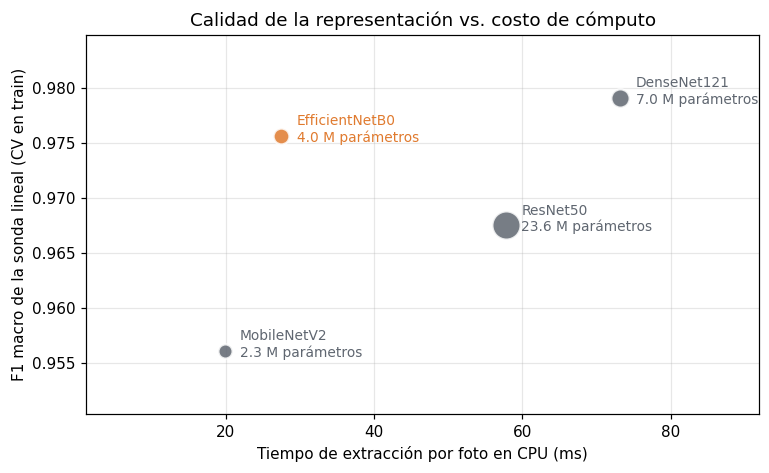

In [4]:
REDES = {
    'EfficientNetB0': (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
    'MobileNetV2': (keras.applications.MobileNetV2, keras.applications.mobilenet_v2.preprocess_input),
    'ResNet50': (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input),
    'DenseNet121': (keras.applications.DenseNet121, keras.applications.densenet.preprocess_input),
}

def crear_extractor(nombre):
    constructor, _ = REDES[nombre]
    base = constructor(include_top=False, weights='imagenet', input_shape=TAMANO_CNN + (3,), pooling='avg')
    base.trainable = False   # pesos congelados: la red solo extrae características
    return base

def huella(rutas, nombre):
    # Identifica las fotos exactas, el recorte y la red, para reutilizar embeddings ya calculados
    h = hashlib.md5()
    for r in rutas:
        h.update(os.path.basename(r).encode())
    h.update(json.dumps({'roi': ROI, 'tamano': TAMANO_CNN, 'red': nombre}, sort_keys=True).encode())
    return h.hexdigest()

def extraer_embeddings(extractor, nombre, info):
    # Recorre el tf.data lote por lote y guarda juntos los vectores y las etiquetas de cada lote
    rutas = info['ruta'].tolist()
    cache = os.path.join(CARPETA_MODELOS, f"embeddings_{nombre}_{len(rutas)}.npz")
    firma = huella(rutas, nombre)
    if os.path.exists(cache):
        guardado = np.load(cache)
        if str(guardado['huella']) == firma:
            return guardado['X'], guardado['etiquetas'], float(guardado['ms'])
    @tf.function
    def paso(x):
        return extractor(x, training=False)
    ds = crear_dataset(rutas, info['estado'].map(ESTADOS.index), REDES[nombre][1])
    vectores, etiquetas = [], []
    t0 = time.time()
    for x, e in ds:
        vectores.append(paso(x).numpy())
        etiquetas.append(e.numpy())
    ms = 1000 * (time.time() - t0) / len(rutas)
    X, etiquetas = np.vstack(vectores), np.concatenate(etiquetas)
    np.savez(cache, X=X, etiquetas=etiquetas, ms=ms, huella=firma)
    return X, etiquetas, ms

embeddings, filas = {}, []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
for nombre in REDES:
    extractor = crear_extractor(nombre)
    X_tr, e_tr, ms_tr = extraer_embeddings(extractor, nombre, info_train)
    X_te, e_te, ms_te = extraer_embeddings(extractor, nombre, info_test)
    assert (e_tr == y_estado_train).all() and (e_te == y_estado_test).all(), "Las filas no quedaron alineadas"
    embeddings[nombre] = {'train': X_tr, 'test': X_te}
    sonda = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced'))
    pred_cv = cross_val_predict(sonda, X_tr, y_estado_train, cv=cv)
    filas.append({'Red': nombre,
                  'Parámetros (M)': extractor.count_params() / 1e6,
                  'Tamaño (MB)': extractor.count_params() * 4 / 1e6,
                  'Vector por foto': X_tr.shape[1],
                  'ms por foto (lotes de 32, CPU)': (ms_tr * len(X_tr) + ms_te * len(X_te)) / (len(X_tr) + len(X_te)),
                  'F1 macro (CV, train)': f1_score(y_estado_train, pred_cv, average='macro'),
                  'Recall MAL ROSCADA (CV, train)': recall_score(y_train, (pred_cv != 0).astype(int))})
    del extractor
    keras.backend.clear_session()

tabla_redes = pd.DataFrame(filas).set_index('Red')
mejor_f1 = tabla_redes['F1 macro (CV, train)'].max()
candidatas = tabla_redes[tabla_redes['F1 macro (CV, train)'] >= mejor_f1 - 0.01]
red_elegida = candidatas['ms por foto (lotes de 32, CPU)'].idxmin()
display(tabla_redes.style.format({'Parámetros (M)': '{:.1f}', 'Tamaño (MB)': '{:.1f}', 'ms por foto (lotes de 32, CPU)': '{:.1f}',
                                  'F1 macro (CV, train)': '{:.4f}', 'Recall MAL ROSCADA (CV, train)': '{:.4f}'})
                         .highlight_max(subset=['F1 macro (CV, train)'], color='#cde8c4'))
print(f"Red elegida: {red_elegida} (F1 macro en CV = {tabla_redes.loc[red_elegida, 'F1 macro (CV, train)']:.4f}, "
      f"{tabla_redes.loc[red_elegida, 'ms por foto (lotes de 32, CPU)']:.1f} ms por foto)")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for nombre, fila in tabla_redes.iterrows():
    color = '#E07A2E' if nombre == red_elegida else '#5F6670'
    ax.scatter(fila['ms por foto (lotes de 32, CPU)'], fila['F1 macro (CV, train)'], s=60 + 12 * fila['Parámetros (M)'],
               color=color, alpha=0.85, edgecolor='white', linewidth=1.5, zorder=3)
    ax.annotate(f"{nombre}\n{fila['Parámetros (M)']:.1f} M parámetros", (fila['ms por foto (lotes de 32, CPU)'], fila['F1 macro (CV, train)']),
                textcoords='offset points', xytext=(10, -4), fontsize=9, color=color)
ax.set_xlabel("Tiempo de extracción por foto en CPU (ms)")
ax.set_ylabel("F1 macro de la sonda lineal (CV en train)")
ax.set_title("Calidad de la representación vs. costo de cómputo")
ax.grid(alpha=0.3)
ax.margins(x=0.35, y=0.25)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "e4_redes.png"), bbox_inches='tight')
plt.show()

### ¿Por qué EfficientNetB0?

- **Separa los estados casi tan bien como la mejor.** DenseNet121 obtuvo el F1 macro más alto (0,9791) y EfficientNetB0 quedó a solo 0,003 (0,9757). Con la regla fijada antes de medir, esa diferencia no justifica una red más lenta.
- **Es 2,7 veces más rápida que DenseNet121:** 27,5 ms contra 73,2 ms por foto en este CPU, y pesa 16 MB.
- **Es la que más tapas mal roscadas detecta** en la validación cruzada (recall de 0,991, el más alto de las cuatro). Ese es el error más caro para la embotelladora.
- **Está diseñada para dar la mayor precisión por operación.** Escala a la vez la profundidad, el ancho y la resolución, y sus bloques MBConv con atención por canal aprovechan mejor cada parámetro. Eso importa porque la cámara corre en el CPU de la planta, y en la Entrega 5 el sistema se llevará a un equipo más pequeño.
- **Las otras dos.** MobileNetV2 es la más liviana, pero pierde 0,02 de F1. ResNet50 es la más pesada (94 MB y 2.048 valores por foto) y queda por debajo de EfficientNetB0 y de DenseNet121.

## 5. Embeddings y tabla para AutoGluon

La red elegida, congelada y sin su capa de clasificación, convierte cada recorte en un vector: el **embedding** de la foto. Con esos vectores se arma un `DataFrame` con **una fila por foto**, una columna por número del vector (`f_0`, `f_1`, ...) y la columna `estado` con la etiqueta.

La alineación es exacta por construcción: las etiquetas viajan dentro del mismo `tf.data` que las imágenes, y cada lote entrega a la vez sus vectores y sus etiquetas. La celda anterior ya comprobó que esas etiquetas coinciden, fila por fila, con las de las fotos originales.

df_train: 1994 filas x 1281 columnas (1280 características + 'estado')
df_test:  855 filas x 1281 columnas


,foto,f_0,f_1,f_2,f_3,f_1279,estado
889,20241029_130620_jpg.rf.9,-0.1140,-0.0826,0.2844,-0.0801,0.2964,Roscada
1672,20241101_123519_jpg.rf.f,0.0303,-0.0594,0.8596,0.3467,-0.0962,Floja
414,20241029_115930_jpg.rf.6,-0.1042,-0.2033,-0.1523,0.8402,-0.0982,Roscada
1599,20241101_114724_jpg.rf.2,-0.0888,0.2417,0.4855,0.3889,0.0234,Sin tapa
849,20241029_130353_jpg.rf.3,-0.1226,-0.1093,0.0443,0.5895,0.1165,Roscada
1658,20241101_122446_jpg.rf.8,-0.0772,-0.1077,0.6727,0.5264,0.1567,Sin tapa


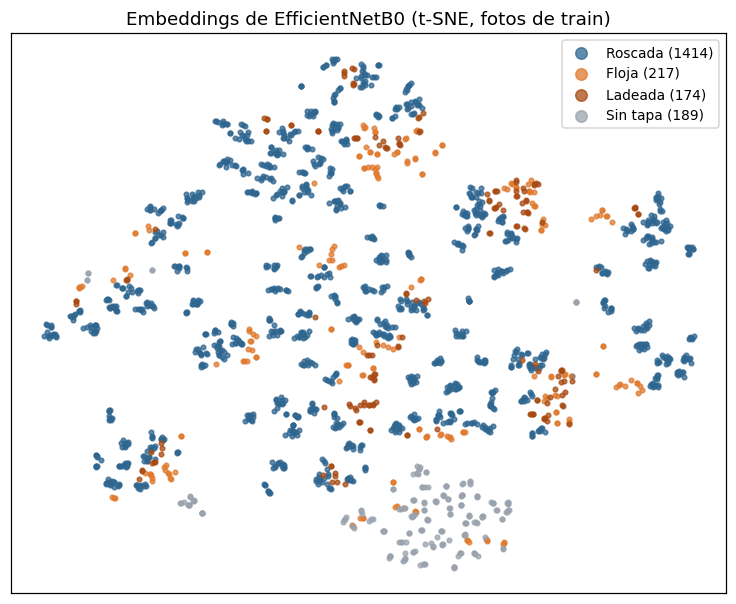

In [5]:
X_train_emb, X_test_emb = embeddings[red_elegida]['train'], embeddings[red_elegida]['test']
columnas = [f'f_{i}' for i in range(X_train_emb.shape[1])]

df_train = pd.DataFrame(X_train_emb, columns=columnas)
df_train['estado'] = info_train['estado'].to_numpy()
df_test = pd.DataFrame(X_test_emb, columns=columnas)
df_test['estado'] = info_test['estado'].to_numpy()

assert len(df_train) == len(info_train) and len(df_test) == len(info_test)
assert df_train[columnas].notna().all().all() and df_test[columnas].notna().all().all()
print(f"df_train: {df_train.shape[0]} filas x {df_train.shape[1]} columnas ({len(columnas)} características + 'estado')")
print(f"df_test:  {df_test.shape[0]} filas x {df_test.shape[1]} columnas")

# Vista de la tabla: algunas columnas, con el nombre de la foto solo como referencia (no entra al modelo)
vista = df_train[columnas[:4] + [columnas[-1], 'estado']].copy()
vista.insert(0, 'foto', info_train['ruta'].map(lambda r: os.path.basename(r)[:24]))
display(vista.sample(6, random_state=SEMILLA).round(4))

# Mapa 2D de los embeddings de train con t-SNE: cada punto es una foto
mapa = TSNE(n_components=2, init='pca', perplexity=30, random_state=SEMILLA).fit_transform(
    StandardScaler().fit_transform(X_train_emb))
colores = {'Roscada': '#2F6690', 'Floja': '#E07A2E', 'Ladeada': '#A84A12', 'Sin tapa': '#9AA3AD'}
fig, ax = plt.subplots(figsize=(6.8, 5.6))
for estado in ESTADOS:
    m = info_train['estado'].to_numpy() == estado
    ax.scatter(mapa[m, 0], mapa[m, 1], s=9, alpha=0.75, color=colores[estado], label=f"{estado} ({m.sum()})")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"Embeddings de {red_elegida} (t-SNE, fotos de train)")
ax.legend(markerscale=2.5, fontsize=9, loc='best')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "e4_tsne.png"), bbox_inches='tight')
plt.show()

## 6. Cabeza de decisión con AutoGluon

Sobre la tabla de embeddings, AutoGluon entrena varios modelos tabulares y al final arma un **ensamble ponderado** con los mejores. La configuración del `TabularPredictor`:

- **Variable objetivo:** `label='estado'`, los cuatro estados de la tapa (`problem_type='multiclass'`). El veredicto ROSCADA o MAL ROSCADA sale del estado predicho.
- **Métrica:** `eval_metric='f1_macro'`. Hay unas 7 tapas roscadas por cada tapa de un tipo de falla, así que la exactitud premiaría acertar solo la clase mayoritaria. El F1 macro le da el mismo peso a cada estado, y la falla más difícil (la tapa ladeada) cuenta igual que las demás.
- **Pesos:** `sample_weight='balance_weight'`, para que cada estado pese lo mismo al entrenar. Es la misma idea de `class_weight='balanced'` de la Entrega 3.
- **Tiempo:** `time_limit=600` segundos.
- **Calidad:** `presets='medium_quality'`, sin *bagging* ni apilamiento. Así cada modelo es uno solo y la predicción en la línea es rápida.
- **Modelos:** los de AutoGluon por defecto (LightGBM en tres variantes, CatBoost, XGBoost, Random Forest, Extra Trees y dos redes neuronales, una en PyTorch y otra en fastai), más una **regresión logística** y **k-NN**. Esos dos se agregan porque los embeddings de una red suelen separarse bien con modelos simples, y k-NN conecta con la Entrega 3.

AutoGluon separa por su cuenta una parte de `train` para **validación**, y con esa parte elige el mejor modelo. El conjunto de prueba no participa en ninguna decisión.

In [6]:
ruta_ag = os.path.join(CARPETA_MODELOS, 'autogluon_e4')
if os.path.exists(ruta_ag):
    shutil.rmtree(ruta_ag)   # cada ejecución entrena desde cero
# Modelos por defecto de AutoGluon + regresión logística + k-NN
MODELOS_AG = get_hyperparameter_config('default')
MODELOS_AG['LR'] = {}
MODELOS_AG['KNN'] = [{'weights': 'uniform', 'ag_args': {'name_suffix': 'Unif'}},
                     {'weights': 'distance', 'ag_args': {'name_suffix': 'Dist'}}]
print("Familias de modelos:", ', '.join(MODELOS_AG))

predictor = TabularPredictor(label='estado', problem_type='multiclass', eval_metric='f1_macro',
                             sample_weight='balance_weight', path=ruta_ag, verbosity=1)
t0 = time.time()
predictor.fit(train_data=df_train, time_limit=TIEMPO_AUTOGLUON, presets='medium_quality', hyperparameters=MODELOS_AG)
print(f"AutoGluon entrenó {len(predictor.model_names())} modelos en {time.time() - t0:.0f} s. "
      f"Mejor según la validación: {predictor.model_best}")

Familias de modelos: NN_TORCH, GBM, CAT, XGB, FASTAI, RF, XT, LR, KNN


	Many features detected (1280), dynamically setting 'colsample_bylevel' to 0.78125 to speed up training (Default = 1).


	To disable this functionality, explicitly specify 'colsample_bylevel' in the model hyperparameters.


Iteration 310: Model size exceeds available memory. Available memory: 2175.20 MB, Estimated model size: 2414.68 MB.


Early stopping model prior to optimal result to avoid OOM error. Please increase available memory to avoid subpar model quality.


AutoGluon entrenó 15 modelos en 584 s. Mejor según la validación: WeightedEnsemble_L2


### Leaderboard de AutoGluon

Cada fila es un modelo. `F1 macro (validación)` es el puntaje con el que AutoGluon elige; `F1 macro (prueba)` se calcula después, con las 855 botellas de prueba, solo para analizar. Hay dos tiempos de predicción, porque no miden lo mismo:

- **En lote:** las 855 fotos en una sola llamada, dividido entre 855. Es el que reporta AutoGluon.
- **Una a la vez:** una foto por llamada, como llegan desde la cámara de la línea. Es el que importa para el tiempo real.

Antes de armar la tabla se agrega un **segundo ensamble**, `WeightedEnsemble_L2_Rapido`. AutoGluon lo arma con `fit_weighted_ensemble`, con el mismo método del primero, pero solo con los modelos que responden una foto en 20 ms o menos. Así se ve cuánta precisión cuesta la velocidad.

Modelos base de 20 ms o menos por foto: NeuralNetFastAI, LightGBMXT, LightGBM, XGBoost, LightGBMLarge


,Modelo,F1 macro (validación),F1 macro (prueba),Exactitud (prueba),Exactitud balanceada (prueba),ms por foto (en lote),ms por foto (una a la vez),Entrenamiento (s),Combina
1,WeightedEnsemble_L2,0.9796,0.9753,0.9895,0.9739,0.74,383.8,24.4,"NeuralNetFastAI, KNeighborsDist, LinearModel"
2,WeightedEnsemble_L2_Rapido,0.9758,0.9725,0.9871,0.9694,0.11,21.6,47.9,"NeuralNetFastAI, XGBoost"
3,LinearModel,0.9624,0.9786,0.9906,0.9766,0.57,278.1,18.0,
4,NeuralNetFastAI,0.9622,0.9671,0.9848,0.9707,0.06,11.5,5.9,
5,NeuralNetTorch,0.9518,0.9706,0.9871,0.9667,0.52,321.7,12.5,
6,LightGBMXT,0.8934,0.9114,0.9591,0.8993,0.02,13.3,27.5,
7,XGBoost,0.8913,0.8889,0.9450,0.8690,0.05,8.8,41.9,
8,LightGBM,0.8776,0.8954,0.9520,0.8741,0.02,12.9,46.1,
9,CatBoost,0.8765,0.9255,0.9649,0.9125,0.05,44.2,247.1,
10,LightGBMLarge,0.8177,0.8059,0.9111,0.7808,0.01,12.5,166.6,


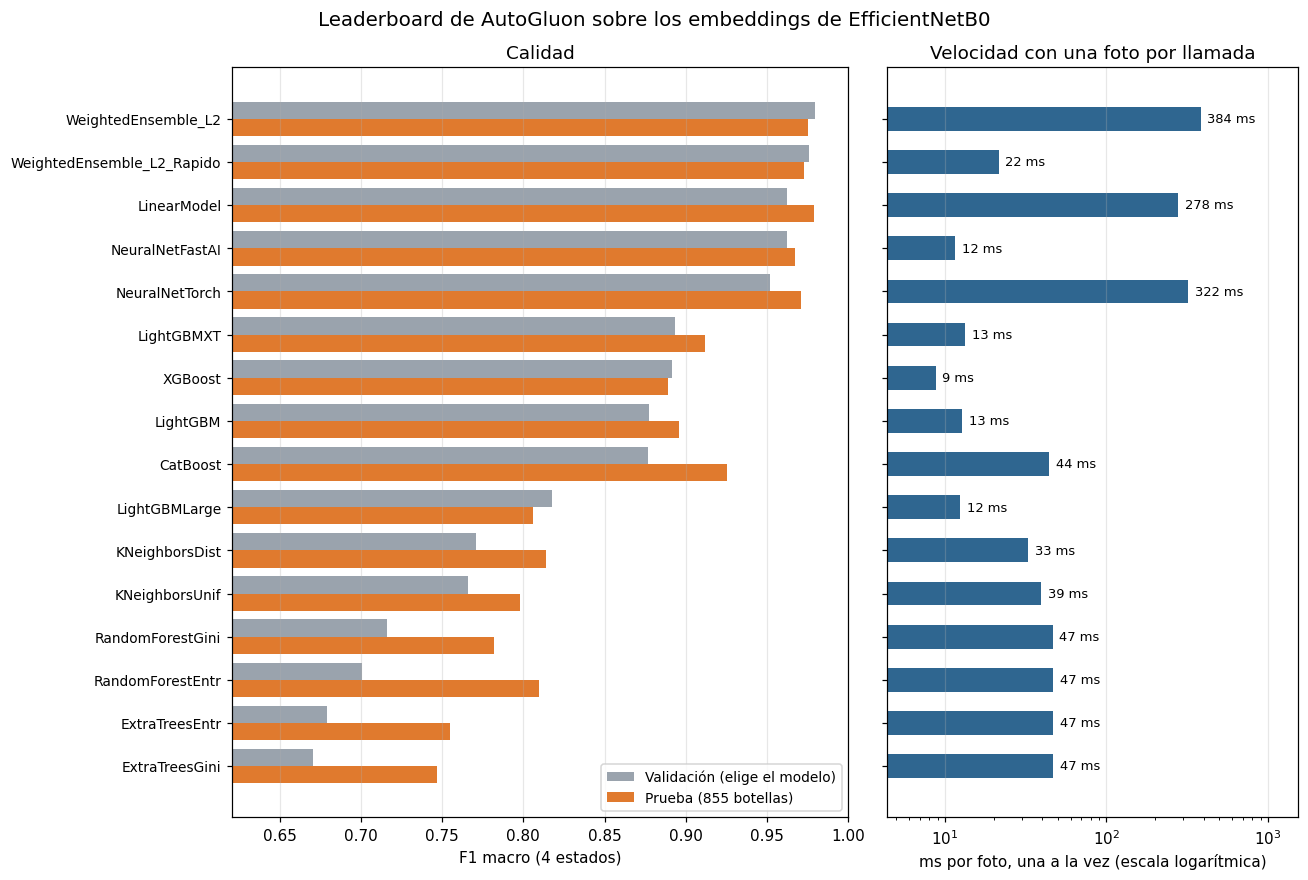

In [7]:
# Tiempo con UNA foto por llamada, como llega desde la cámara. Los modelos quedan en memoria, como en producción.
predictor.persist(models='all', max_memory=None)   # todos juntos pesan pocos MB
filas_lat = np.random.default_rng(SEMILLA).choice(len(df_test), 23, replace=False)

def ms_una_foto(modelo):
    tiempos = []
    for k, i in enumerate(filas_lat):
        t0 = time.perf_counter()
        predictor.predict_proba(df_test.iloc[[i]][columnas], model=modelo)
        if k >= 3:   # las tres primeras llamadas solo calientan
            tiempos.append(1000 * (time.perf_counter() - t0))
    return float(np.median(tiempos))

ms_una = {m: ms_una_foto(m) for m in predictor.model_names()}

# Segundo ensamble: la misma selección de AutoGluon, pero solo con modelos base de 20 ms o menos por foto
LIMITE_RAPIDO_MS = 20
base = [m for m in predictor.model_names() if not m.startswith('WeightedEnsemble')]
rapidos = [m for m in base if ms_una[m] <= LIMITE_RAPIDO_MS] or sorted(base, key=ms_una.get)[:3]   # en un equipo lento: los 3 más rápidos
ensamble_rapido = predictor.fit_weighted_ensemble(base_models=rapidos, name_suffix='_Rapido')[0]
predictor.persist(models=[ensamble_rapido], with_ancestors=False, max_memory=None)
ms_una[ensamble_rapido] = ms_una_foto(ensamble_rapido)
print(f"Modelos base de {LIMITE_RAPIDO_MS} ms o menos por foto: {', '.join(rapidos)}")

lb = predictor.leaderboard(df_test, extra_metrics=['accuracy', 'balanced_accuracy'], extra_info=True, display=False)
tabla_lb = pd.DataFrame({
    'Modelo': lb['model'],
    'F1 macro (validación)': lb['score_val'],
    'F1 macro (prueba)': lb['score_test'],
    'Exactitud (prueba)': lb['accuracy'],
    'Exactitud balanceada (prueba)': lb['balanced_accuracy'],
    'ms por foto (en lote)': 1000 * lb['pred_time_test'] / len(df_test),
    'ms por foto (una a la vez)': lb['model'].map(ms_una),
    'Entrenamiento (s)': lb['fit_time'],
    'Combina': [', '.join(a) if len(a) else '' for a in lb['ancestors']],
}).sort_values('F1 macro (validación)', ascending=False).reset_index(drop=True)
tabla_lb.index += 1
display(tabla_lb.style.format({c: '{:.4f}' for c in tabla_lb.columns if 'F1' in c or 'Exactitud' in c} |
                              {'ms por foto (en lote)': '{:.2f}', 'ms por foto (una a la vez)': '{:.1f}',
                               'Entrenamiento (s)': '{:.1f}'})
                      .background_gradient(subset=['F1 macro (prueba)'], cmap='Greens'))

orden = tabla_lb.sort_values('F1 macro (validación)')
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 0.42 * len(orden) + 1.4), sharey=True,
                              gridspec_kw={'width_ratios': [3, 2]})
pos = np.arange(len(orden))
ax.barh(pos + 0.2, orden['F1 macro (validación)'], height=0.4, color='#9AA3AD', label='Validación (elige el modelo)')
ax.barh(pos - 0.2, orden['F1 macro (prueba)'], height=0.4, color='#E07A2E', label='Prueba (855 botellas)')
ax.set_yticks(pos)
ax.set_yticklabels(orden['Modelo'], fontsize=9)
ax.set_xlim(max(0.0, orden[['F1 macro (validación)', 'F1 macro (prueba)']].min().min() - 0.05), 1.0)
ax.set_xlabel("F1 macro (4 estados)")
ax.set_title("Calidad")
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)
ms_orden = orden['ms por foto (una a la vez)'].to_numpy()
ax2.barh(pos, ms_orden, height=0.55, color='#2F6690')
for p_, v in zip(pos, ms_orden):
    ax2.text(v * 1.1, p_, f"{v:.0f} ms", va='center', fontsize=8.5)
ax2.set_xscale('log')
ax2.set_xlim(max(0.5, ms_orden.min() / 2), ms_orden.max() * 4)
ax2.set_xlabel("ms por foto, una a la vez (escala logarítmica)")
ax2.set_title("Velocidad con una foto por llamada")
ax2.grid(axis='x', alpha=0.3)
fig.suptitle("Leaderboard de AutoGluon sobre los embeddings de " + red_elegida, fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "e4_leaderboard.png"), bbox_inches='tight')
plt.show()

### Análisis del leaderboard

- **Ganan los modelos que usan todo el vector a la vez.** Los cuatro primeros (el ensamble, la regresión logística y las dos redes neuronales) pasan de 0,95 de F1 macro en validación. El embedding de EfficientNetB0 deja los estados casi separados por planos, y eso es justo lo que aprovechan un modelo lineal o una red pequeña.
- **Los árboles quedan atrás.** LightGBM, XGBoost y CatBoost se quedan entre 0,82 y 0,89, y Random Forest y Extra Trees no pasan de 0,72. Un árbol decide mirando una columna a la vez, y en un embedding la información está repartida en cientos de columnas que aportan poco cada una. Es lo mismo que le pasó al Random Forest con PCA en la Entrega 3. CatBoost, además, se detuvo antes de tiempo por falta de memoria (el aviso de la celda de entrenamiento).
- **k-NN no pasa de 0,77.** La distancia entre dos embeddings mezcla lo que importa (la tapa) con lo que no: el tipo de botella y la luz de cada sesión, que en el t-SNE forman grupos propios.
- **El ensamble gana porque combina modelos que fallan en fotos distintas.** `WeightedEnsemble_L2` mezcla la regresión logística, la red de fastai y k-NN, y llega a 0,980 en validación, más que cualquiera de los tres por separado.
- **Validación y prueba cuentan la misma historia.** Los grupos se mantienen en las dos columnas y ningún modelo se desploma en prueba. La regresión logística sola saca el mejor F1 en prueba (0,979), pero el modelo se elige por validación, no por prueba.
- **En lote todos son rápidos; una foto a la vez, no.** En lote, ningún modelo pasa de 1 ms por foto. Con una foto por llamada, la regresión logística y la red de PyTorch tardan unos 300 ms: antes de predecir, su preprocesamiento transforma por separado cada columna sesgada del embedding, y ese costo fijo ya no se reparte entre 855 fotos. Por eso el ensamble completo tarda casi 0,4 s por foto, mientras que el ensamble rápido (fastai + XGBoost) responde en unos 20 ms y pierde solo 0,004 de F1 en validación.

### Qué modelo va a la línea

La línea entrega una botella cada **1,5 s** (2.400 por hora). **Regla:** va a la línea el modelo con mejor F1 macro en **validación** entre los que responden una foto en menos de la mitad de ese ciclo, 750 ms. La otra mitad queda para la cámara, el recorte, la red y el expulsor. El conjunto de prueba no participa en esta decisión.

In [8]:
CICLO_LINEA_MS = 3600 * 1000 / 2400   # 2.400 botellas por hora: una cada 1.500 ms
cumplen = tabla_lb[tabla_lb['ms por foto (una a la vez)'] <= CICLO_LINEA_MS / 2]
modelo_linea = cumplen['Modelo'].iloc[0]   # la tabla ya está ordenada por F1 en validación
predictor.set_model_best(modelo_linea, save_trainer=True)
resumen = tabla_lb.set_index('Modelo').loc[list(dict.fromkeys([modelo_linea, ensamble_rapido])),
                                          ['Combina', 'F1 macro (validación)', 'F1 macro (prueba)', 'ms por foto (una a la vez)']]
display(resumen.style.format({'F1 macro (validación)': '{:.4f}', 'F1 macro (prueba)': '{:.4f}',
                              'ms por foto (una a la vez)': '{:.1f}'}))
print(f"Va a la línea: {modelo_linea} ({ms_una[modelo_linea]:.0f} ms por foto, límite {CICLO_LINEA_MS / 2:.0f} ms)")

# Para producción se guarda una copia mínima con solo los modelos que usa el elegido
ruta_despliegue = os.path.join(CARPETA_MODELOS, 'autogluon_e4_despliegue')
if os.path.exists(ruta_despliegue):
    shutil.rmtree(ruta_despliegue)
logging.getLogger('autogluon').setLevel(logging.ERROR)   # sin el aviso de AutoGluon al copiar
predictor.clone_for_deployment(ruta_despliegue, model=modelo_linea)
predictor.unpersist()

def tamano_mb(ruta):
    if os.path.isfile(ruta):
        return os.path.getsize(ruta) / 1e6
    return sum(os.path.getsize(os.path.join(d, f)) for d, _, archivos in os.walk(ruta) for f in archivos) / 1e6

print(f"Copia para desplegar: {tamano_mb(ruta_despliegue):.1f} MB en {ruta_despliegue}")

,Combina,F1 macro (validación),F1 macro (prueba),ms por foto (una a la vez)
Modelo,,,,
WeightedEnsemble_L2,"NeuralNetFastAI, KNeighborsDist, LinearModel",0.9796,0.9753,383.8
WeightedEnsemble_L2_Rapido,"NeuralNetFastAI, XGBoost",0.9758,0.9725,21.6


Va a la línea: WeightedEnsemble_L2 (384 ms por foto, límite 750 ms)


Copia para desplegar: 17.9 MB en modelos\autogluon_e4_despliegue


## 7. Evaluación en las 855 botellas de prueba

Se evalúa el modelo que va a la línea. Primero, lo que predice AutoGluon: los **cuatro estados**. Después, el **veredicto del producto**: si el estado predicho no es `Roscada`, la botella se aparta como MAL ROSCADA.

Reporte de clasificación: cuatro estados


,Precision,Recall,F1-Score,Botellas
Roscada,0.997,1.000,0.998,606
Floja,0.989,0.936,0.962,94
Ladeada,0.959,0.959,0.959,74
Sin tapa,0.964,1.000,0.982,81
Exactitud,,,0.989,855
Promedio macro,0.977,0.974,0.975,855
Promedio ponderado,0.990,0.989,0.989,855


Reporte de clasificación: veredicto del producto


,Precision,Recall,F1-Score,Botellas
ROSCADA,0.997,1.000,0.998,606
MAL ROSCADA,1.000,0.992,0.996,249
Exactitud,,,0.998,855
Promedio macro,0.998,0.996,0.997,855
Promedio ponderado,0.998,0.998,0.998,855


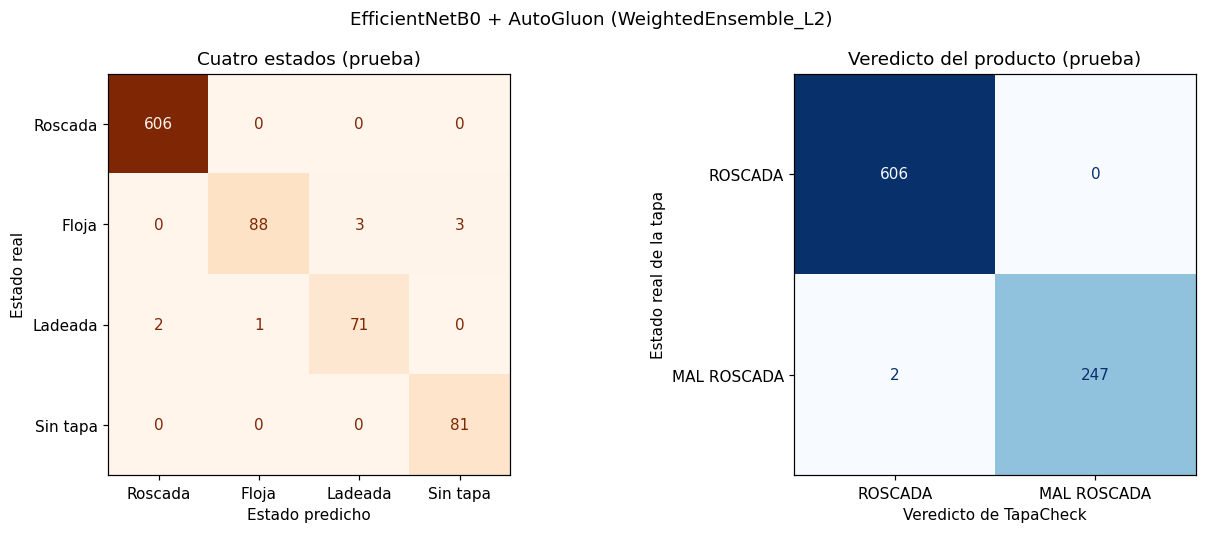

In [9]:
proba = predictor.predict_proba(df_test)[ESTADOS]
estado_pred = predictor.predict(df_test).to_numpy()
estado_real = df_test['estado'].to_numpy()
y_pred = (estado_pred != 'Roscada').astype(int)
p_mal = 1 - proba['Roscada'].to_numpy()   # probabilidad de que la tapa esté mal

print("Reporte de clasificación: cuatro estados")
rep4 = pd.DataFrame(classification_report(estado_real, estado_pred, labels=ESTADOS, output_dict=True, zero_division=0)).T
rep4 = rep4.rename(index={'macro avg': 'Promedio macro', 'weighted avg': 'Promedio ponderado', 'accuracy': 'Exactitud'},
                   columns={'precision': 'Precision', 'recall': 'Recall', 'f1-score': 'F1-Score', 'support': 'Botellas'})
rep4.loc['Exactitud', ['Precision', 'Recall', 'Botellas']] = [np.nan, np.nan, len(estado_real)]
display(rep4.style.format({'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1-Score': '{:.3f}', 'Botellas': '{:.0f}'}, na_rep=''))

print("Reporte de clasificación: veredicto del producto")
rep2 = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASES, output_dict=True, zero_division=0)).T
rep2 = rep2.rename(index={'macro avg': 'Promedio macro', 'weighted avg': 'Promedio ponderado', 'accuracy': 'Exactitud'},
                   columns={'precision': 'Precision', 'recall': 'Recall', 'f1-score': 'F1-Score', 'support': 'Botellas'})
rep2.loc['Exactitud', ['Precision', 'Recall', 'Botellas']] = [np.nan, np.nan, len(y_test)]
display(rep2.style.format({'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1-Score': '{:.3f}', 'Botellas': '{:.0f}'}, na_rep=''))

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.9), gridspec_kw={'width_ratios': [1.35, 1]})
ConfusionMatrixDisplay(confusion_matrix(estado_real, estado_pred, labels=ESTADOS), display_labels=ESTADOS).plot(
    ax=axes[0], cmap='Oranges', colorbar=False)
axes[0].set_title("Cuatro estados (prueba)")
axes[0].set_xlabel("Estado predicho"); axes[0].set_ylabel("Estado real")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASES).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title("Veredicto del producto (prueba)")
axes[1].set_xlabel("Veredicto de TapaCheck"); axes[1].set_ylabel("Estado real de la tapa")
plt.suptitle(f"{red_elegida} + AutoGluon ({predictor.model_best})", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "e4_matriz_confusion.png"), bbox_inches='tight')
plt.show()

### Curvas ROC-AUC y el sistema de la Entrega 3

A la izquierda, una curva por estado (uno contra el resto). A la derecha, la curva del **veredicto**, que usa como puntaje la probabilidad de que la tapa esté mal (1 − P(Roscada)). Se compara con el sistema de la Entrega 3 (Fusión HOG + LBP + GLCM, PCA y SVM), cargado desde `modelos/tapacheck.joblib` y evaluado aquí mismo sobre las **mismas 855 fotos**. Los puntos marcan dónde opera cada sistema con su umbral normal.

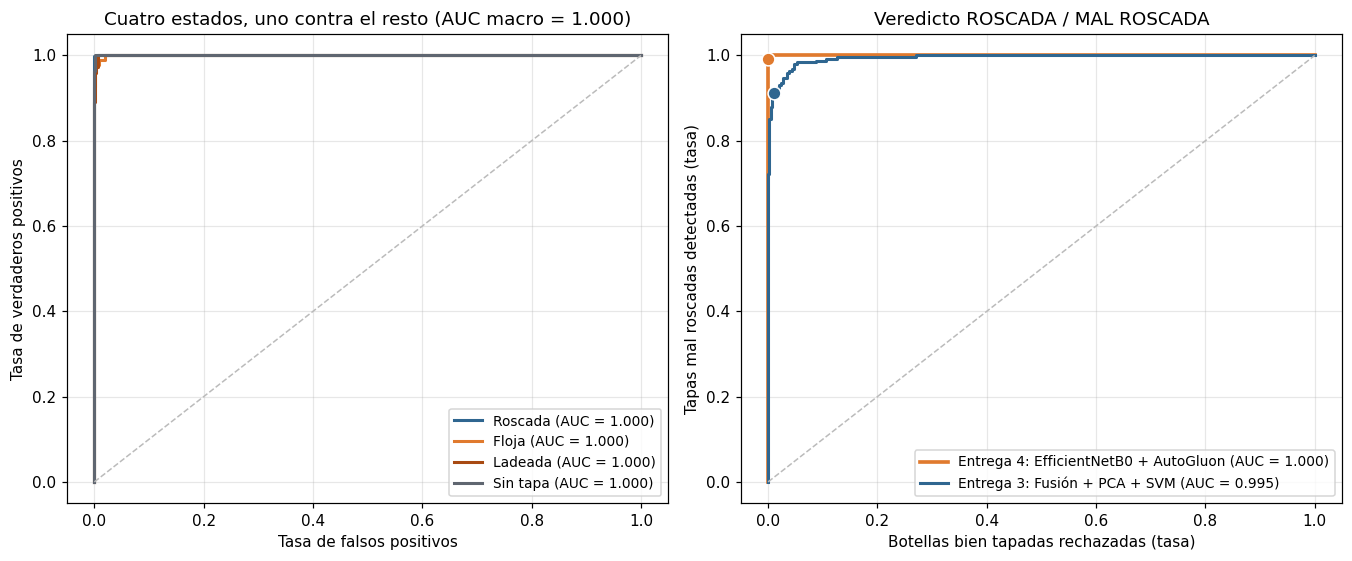

,Botellas,Estado acertado E4 (%),Veredicto acertado E4 (%),Veredicto acertado E3 (%)
Estado real,,,,
Roscada,606,100.0,100.0,99.0
Floja,94,93.6,100.0,96.8
Ladeada,74,95.9,97.3,75.7
Sin tapa,81,100.0,100.0,98.8


In [10]:
# --- Sistema de la Entrega 3, con exactamente el mismo recorte y los mismos descriptores ---
ruta_e3 = os.path.join(CARPETA_MODELOS, 'tapacheck.joblib')
e3 = joblib.load(ruta_e3) if os.path.exists(ruta_e3) else None

def recorte_gris_e3(gris):
    alto, ancho = gris.shape[:2]
    lado = int(round(e3['roi']['lado'] * ancho))
    x0, y0 = int(round(e3['roi']['cx'] * ancho - lado / 2)), int(round(e3['roi']['cy'] * alto - lado / 2))
    x1, y1 = x0 + lado, y0 + lado
    borde = max(0, -x0, -y0, x1 - ancho, y1 - alto)
    if borde:
        gris = cv2.copyMakeBorder(gris, borde, borde, borde, borde, cv2.BORDER_REPLICATE)
        x0, y0, x1, y1 = x0 + borde, y0 + borde, x1 + borde, y1 + borde
    return cv2.resize(gris[y0:y1, x0:x1], e3['tamano'], interpolation=cv2.INTER_AREA)

def vector_e3(img):
    f_hog = hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')
    lbp = local_binary_pattern(img, P=8, R=1, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), range=(0, 10))
    hist = hist.astype("float32") / (hist.sum() + 1e-7)
    glcm = graycomatrix((img // 4).astype(np.uint8), distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=64, symmetric=True, normed=True)
    f_glcm = np.concatenate([graycoprops(glcm, p).ravel() for p in ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']])
    return np.hstack([f_hog, hist, f_glcm])

def puntaje_e3(rutas):
    F = np.array([vector_e3(recorte_gris_e3(cv2.imread(r, cv2.IMREAD_GRAYSCALE))) for r in rutas])
    X = e3['pca'].transform(e3['scaler_fusion'].transform(F))
    return e3['modelo'].decision_function(X), e3['modelo'].predict(X)

if e3 is not None and e3['descriptor'] == 'Fusión + PCA':
    puntaje3, y_pred_e3 = puntaje_e3(info_test['ruta'])
else:
    puntaje3 = y_pred_e3 = None
    print("No se encontró el modelo de la Entrega 3 (ejecute primero TapaCheck_inspeccion_tapas.ipynb); se omite la comparación.")

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.2))
colores_estado = {'Roscada': '#2F6690', 'Floja': '#E07A2E', 'Ladeada': '#A84A12', 'Sin tapa': '#5F6670'}
auc_estados = {}
for estado in ESTADOS:
    fpr, tpr, _ = roc_curve(estado_real == estado, proba[estado])
    auc_estados[estado] = roc_auc_score(estado_real == estado, proba[estado])
    axes[0].plot(fpr, tpr, color=colores_estado[estado], lw=2, label=f"{estado} (AUC = {auc_estados[estado]:.3f})")
auc_macro = roc_auc_score(y_estado_test, proba[ESTADOS].to_numpy(), multi_class='ovr', average='macro')
axes[0].plot([0, 1], [0, 1], ls='--', color='#BBBBBB', lw=1)
axes[0].set_title(f"Cuatro estados, uno contra el resto (AUC macro = {auc_macro:.3f})")
axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(loc='lower right', fontsize=9)

auc_e4 = roc_auc_score(y_test, p_mal)
fpr, tpr, _ = roc_curve(y_test, p_mal)
axes[1].plot(fpr, tpr, color='#E07A2E', lw=2.4, label=f"Entrega 4: {red_elegida} + AutoGluon (AUC = {auc_e4:.3f})")
tn4, fp4, fn4, tp4 = confusion_matrix(y_test, y_pred).ravel()
axes[1].scatter(fp4 / (fp4 + tn4), tp4 / (tp4 + fn4), color='#E07A2E', s=70, zorder=4, edgecolor='white')
if puntaje3 is not None:
    auc_e3 = roc_auc_score(y_test, puntaje3)
    fpr3, tpr3, _ = roc_curve(y_test, puntaje3)
    axes[1].plot(fpr3, tpr3, color='#2F6690', lw=2, label=f"Entrega 3: Fusión + PCA + SVM (AUC = {auc_e3:.3f})")
    tn3, fp3, fn3, tp3 = confusion_matrix(y_test, y_pred_e3).ravel()
    axes[1].scatter(fp3 / (fp3 + tn3), tp3 / (tp3 + fn3), color='#2F6690', s=70, zorder=4, edgecolor='white')
axes[1].plot([0, 1], [0, 1], ls='--', color='#BBBBBB', lw=1)
axes[1].set_title("Veredicto ROSCADA / MAL ROSCADA")
axes[1].set_xlabel("Botellas bien tapadas rechazadas (tasa)"); axes[1].set_ylabel("Tapas mal roscadas detectadas (tasa)")
axes[1].legend(loc='lower right', fontsize=9)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "e4_roc.png"), bbox_inches='tight')
plt.show()

# Acierto por tipo de tapa, comparado con la Entrega 3
filas = []
for estado in ESTADOS:
    m = estado_real == estado
    fila = {'Estado real': estado, 'Botellas': int(m.sum()),
            'Estado acertado E4 (%)': round(100 * (estado_pred[m] == estado).mean(), 1),
            'Veredicto acertado E4 (%)': round(100 * (y_pred[m] == y_test[m]).mean(), 1)}
    if y_pred_e3 is not None:
        fila['Veredicto acertado E3 (%)'] = round(100 * (y_pred_e3[m] == y_test[m]).mean(), 1)
    filas.append(fila)
display(pd.DataFrame(filas).set_index('Estado real'))

## 8. Comparación con la Entrega 3 (técnicas clásicas)

Los dos sistemas se miden igual: las mismas 855 fotos, el mismo veredicto y los mismos supuestos de costo de la Entrega 3. El tiempo es **de punta a punta y foto por foto**: leer la imagen del disco, recortar, extraer características y decidir, como pasa en la línea.

In [11]:
# --- Tiempo por foto, de punta a punta (una foto a la vez, como en la línea) ---
predictor_linea = TabularPredictor.load(ruta_despliegue, verbosity=0)
predictor_linea.persist()   # deja los modelos en memoria para responder rápido
extractor = crear_extractor(red_elegida)
preprocesar = REDES[red_elegida][1]

@tf.function(input_signature=[tf.TensorSpec([], tf.string)])
def embedding_de(ruta):
    # Leer, recortar, normalizar y pasar por la red en un solo grafo de TensorFlow (más rápido que paso a paso)
    return extractor(preprocesar(cargar_y_recortar(ruta))[tf.newaxis], training=False)

def inspeccionar(ruta_imagen):
    # Recibe solo la foto de la cámara: recorte fijo -> red congelada -> AutoGluon -> estado y veredicto
    t0 = time.perf_counter()
    fila = pd.DataFrame(embedding_de(tf.constant(ruta_imagen)).numpy(), columns=columnas)
    probabilidades = predictor_linea.predict_proba(fila).iloc[0][ESTADOS]
    estado = probabilidades.idxmax()
    return estado, CLASES[int(estado != 'Roscada')], probabilidades, 1000 * (time.perf_counter() - t0)

def inspeccionar_e3(ruta_imagen):
    t0 = time.perf_counter()
    img = recorte_gris_e3(cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE))
    pred = e3['modelo'].predict(e3['pca'].transform(e3['scaler_fusion'].transform([vector_e3(img)])))[0]
    return CLASES[int(pred)], 1000 * (time.perf_counter() - t0)

rng = np.random.default_rng(SEMILLA)
muestra = info_test['ruta'].to_numpy()[rng.choice(len(info_test), 60, replace=False)]
inspeccionar(muestra[0]); inspeccionar(muestra[1])   # las primeras llamadas preparan la red y los modelos
ms_e4 = np.array([inspeccionar(r)[3] for r in muestra])
ms_e3 = np.array([inspeccionar_e3(r)[1] for r in muestra]) if e3 is not None else None

# --- Costo mensual de errores, con los mismos supuestos de la Entrega 3 ---
BOTELLAS_HORA, HORAS_DIA, DIAS_MES = 2_400, 16, 26
TASA_MAL_ROSCADA = 0.005
COSTO_ESCAPE, COSTO_FALSO_RECHAZO = 12_000, 500          # COP
DETECCION_MANUAL, FALSO_RECHAZO_MANUAL = 0.80, 0.01       # inspección a ojo (See, 2015)

def costo_mensual(deteccion, falso_rechazo):
    malas = BOTELLAS_HORA * HORAS_DIA * TASA_MAL_ROSCADA
    buenas = BOTELLAS_HORA * HORAS_DIA - malas
    escapes, rechazos = malas * (1 - deteccion), buenas * falso_rechazo
    return DIAS_MES * escapes, DIAS_MES * rechazos, DIAS_MES * (escapes * COSTO_ESCAPE + rechazos * COSTO_FALSO_RECHAZO)

def fila_sistema(nombre, y_real, pred, puntaje, ms, mb):
    tn_, fp_, fn_, tp_ = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    escapes, rechazos, costo = costo_mensual(tp_ / (tp_ + fn_), fp_ / (fp_ + tn_))
    return {'Sistema': nombre,
            'Exactitud': f"{100 * (tp_ + tn_) / len(y_real):.1f} %",
            'F1-Score (MAL ROSCADA)': f"{f1_score(y_real, pred):.4f}",
            'Mal roscadas detectadas': f"{100 * tp_ / (tp_ + fn_):.1f} %  ({tp_} de {tp_ + fn_})",
            'Bien tapadas rechazadas': f"{100 * fp_ / (fp_ + tn_):.1f} %  ({fp_} de {fp_ + tn_})",
            'AUC ROC': f"{roc_auc_score(y_real, puntaje):.4f}",
            'ms por foto (mediana)': f"{np.median(ms):.0f} ms",
            'Tamaño del modelo': f"{mb:.0f} MB",
            'Mal tapadas al cliente (mes)': f"{escapes:,.0f}",
            'Costo mensual de errores (COP)': f"${costo:,.0f}"}

mb_e4 = extractor.count_params() * 4 / 1e6 + tamano_mb(ruta_despliegue)
filas = []
if e3 is not None:
    filas.append(fila_sistema('Entrega 3: Fusión + PCA + SVM', y_test, y_pred_e3, puntaje3, ms_e3, tamano_mb(ruta_e3)))
filas.append(fila_sistema(f'Entrega 4: {red_elegida} + AutoGluon', y_test, y_pred, p_mal, ms_e4, mb_e4))
comparacion = pd.DataFrame(filas).set_index('Sistema').T
esc_m, rech_m, costo_m = costo_mensual(DETECCION_MANUAL, FALSO_RECHAZO_MANUAL)
comparacion['Inspección manual (referencia)'] = ['', '', '80 % (See, 2015)', '1 % (supuesto)', '', '', '',
                                                 f"{esc_m:,.0f}", f"${costo_m:,.0f}"]
display(comparacion)
print(f"Latencia E4: mediana {np.median(ms_e4):.0f} ms, percentil 95 {np.percentile(ms_e4, 95):.0f} ms "
      f"-> {1000 / np.median(ms_e4):.1f} fotos por segundo en CPU; la línea pide {1000 / CICLO_LINEA_MS:.2f} "
      f"(una botella cada {CICLO_LINEA_MS:.0f} ms)")
if ms_e3 is not None:
    print(f"Latencia E3: mediana {np.median(ms_e3):.0f} ms, percentil 95 {np.percentile(ms_e3, 95):.0f} ms")

Sistema,Entrega 3: Fusión + PCA + SVM,Entrega 4: EfficientNetB0 + AutoGluon,Inspección manual (referencia)
Exactitud,96.7 %,99.8 %,
F1-Score (MAL ROSCADA),0.9419,0.9960,
Mal roscadas detectadas,91.2 % (227 de 249),99.2 % (247 de 249),"80 % (See, 2015)"
Bien tapadas rechazadas,1.0 % (6 de 606),0.0 % (0 de 606),1 % (supuesto)
AUC ROC,0.9948,1.0000,
ms por foto (mediana),24 ms,404 ms,
Tamaño del modelo,77 MB,34 MB,
Mal tapadas al cliente (mes),441,40,998
Costo mensual de errores (COP),"$10,210,584","$481,157","$16,947,840"


Latencia E4: mediana 404 ms, percentil 95 435 ms -> 2.5 fotos por segundo en CPU; la línea pide 0.67 (una botella cada 1500 ms)
Latencia E3: mediana 24 ms, percentil 95 25 ms


### Prueba extra: días de captura que el modelo nunca vio

En la Entrega 3 se encontró la principal limitación del dataset: casi todas las tapas roscadas se fotografiaron el 29 y el 30 de octubre, y las mal roscadas entre el 31 de octubre y el 4 de noviembre. Con días nunca vistos, el sistema clásico bajó a **77,4 %** de tapas mal roscadas detectadas y subió a **6,3 %** de botellas buenas rechazadas.

Aquí se repite exactamente el mismo experimento con los embeddings y AutoGluon (con 300 s de entrenamiento):

- **Entrenamiento:** tapas roscadas del 29 de octubre y mal roscadas del 31 de octubre y del 4 de noviembre.
- **Prueba:** tapas roscadas del 30 de octubre y mal roscadas del 1 de noviembre.

In [12]:
def dia_de(ruta):
    return os.path.basename(ruta)[:8]   # los nombres empiezan por la fecha de captura: 20241030_124240_jpg.rf....

info_todo = pd.concat([info_train, info_test], ignore_index=True)
dias = info_todo['ruta'].map(dia_de).to_numpy()
df_todo = pd.concat([df_train, df_test], ignore_index=True)
y_todo = (df_todo['estado'] != 'Roscada').to_numpy().astype(int)
en_train = ((y_todo == 0) & np.isin(dias, ['20241029'])) | ((y_todo == 1) & np.isin(dias, ['20241031', '20241104']))
en_prueba = ((y_todo == 0) & np.isin(dias, ['20241030'])) | ((y_todo == 1) & np.isin(dias, ['20241101']))

# Resultado de la Entrega 3 en este mismo experimento (TapaCheck_inspeccion_tapas.ipynb)
E3_DIAS = {'Botellas': 693, 'Mal roscadas detectadas': '77.4 %  (178 de 230)',
           'Bien tapadas rechazadas': '6.3 %  (29 de 463)', 'Exactitud': '88.3 %', 'F1-Score': 0.8146}

if en_train.any() and en_prueba.any():
    ruta_dias = os.path.join(CARPETA_MODELOS, 'autogluon_e4_dias')
    if os.path.exists(ruta_dias):
        shutil.rmtree(ruta_dias)
    predictor_dias = TabularPredictor(label='estado', problem_type='multiclass', eval_metric='f1_macro',
                                      sample_weight='balance_weight', path=ruta_dias, verbosity=0)
    predictor_dias.fit(train_data=df_todo[en_train], time_limit=300, presets='medium_quality', hyperparameters=MODELOS_AG)
    pred_dias = (predictor_dias.predict(df_todo[en_prueba]).to_numpy() != 'Roscada').astype(int)
    real_dias = y_todo[en_prueba]
    tn_, fp_, fn_, tp_ = confusion_matrix(real_dias, pred_dias, labels=[0, 1]).ravel()
    tabla_dias = pd.DataFrame({
        'Entrega 3: Fusión + PCA + SVM': E3_DIAS,
        f'Entrega 4: {red_elegida} + AutoGluon': {
            'Botellas': len(real_dias),
            'Mal roscadas detectadas': f"{100 * tp_ / (tp_ + fn_):.1f} %  ({tp_} de {tp_ + fn_})",
            'Bien tapadas rechazadas': f"{100 * fp_ / (fp_ + tn_):.1f} %  ({fp_} de {fp_ + tn_})",
            'Exactitud': f"{100 * (tp_ + tn_) / len(real_dias):.1f} %",
            'F1-Score': round(f1_score(real_dias, pred_dias), 4)}})
    print(f"Entrenamiento: {en_train.sum()} fotos, prueba: {en_prueba.sum()} fotos de días nunca vistos")
    display(tabla_dias)
else:
    print("Esta versión del dataset no tiene los días esperados; se omite la prueba por días.")

Entrenamiento: 2155 fotos, prueba: 693 fotos de días nunca vistos


,Entrega 3: Fusión + PCA + SVM,Entrega 4: EfficientNetB0 + AutoGluon
Botellas,693,693
Mal roscadas detectadas,77.4 % (178 de 230),88.7 % (204 de 230)
Bien tapadas rechazadas,6.3 % (29 de 463),3.9 % (18 de 463)
Exactitud,88.3 %,93.7 %
F1-Score,0.8146,0.9027


## 9. Comprobación en tiempo real: `inspeccionar()`

La función `inspeccionar()` de la sección anterior es lo que corre en la línea: recibe solo la foto de la cámara y devuelve el estado, el veredicto, las probabilidades y el tiempo que tardó. Abajo se prueba con fotos de prueba elegidas al azar, dos por estado, leídas directamente del disco.

Para la exposición, `demo_tiempo_real.py` hace lo mismo **en vivo**: con la cámara del computador (`python demo_tiempo_real.py --camara 0`) o con un **flujo continuo** de fotos de prueba que simula la banda transportadora (`python demo_tiempo_real.py`). En pantalla muestra el veredicto, la probabilidad de cada estado, la latencia y las fotos por segundo.

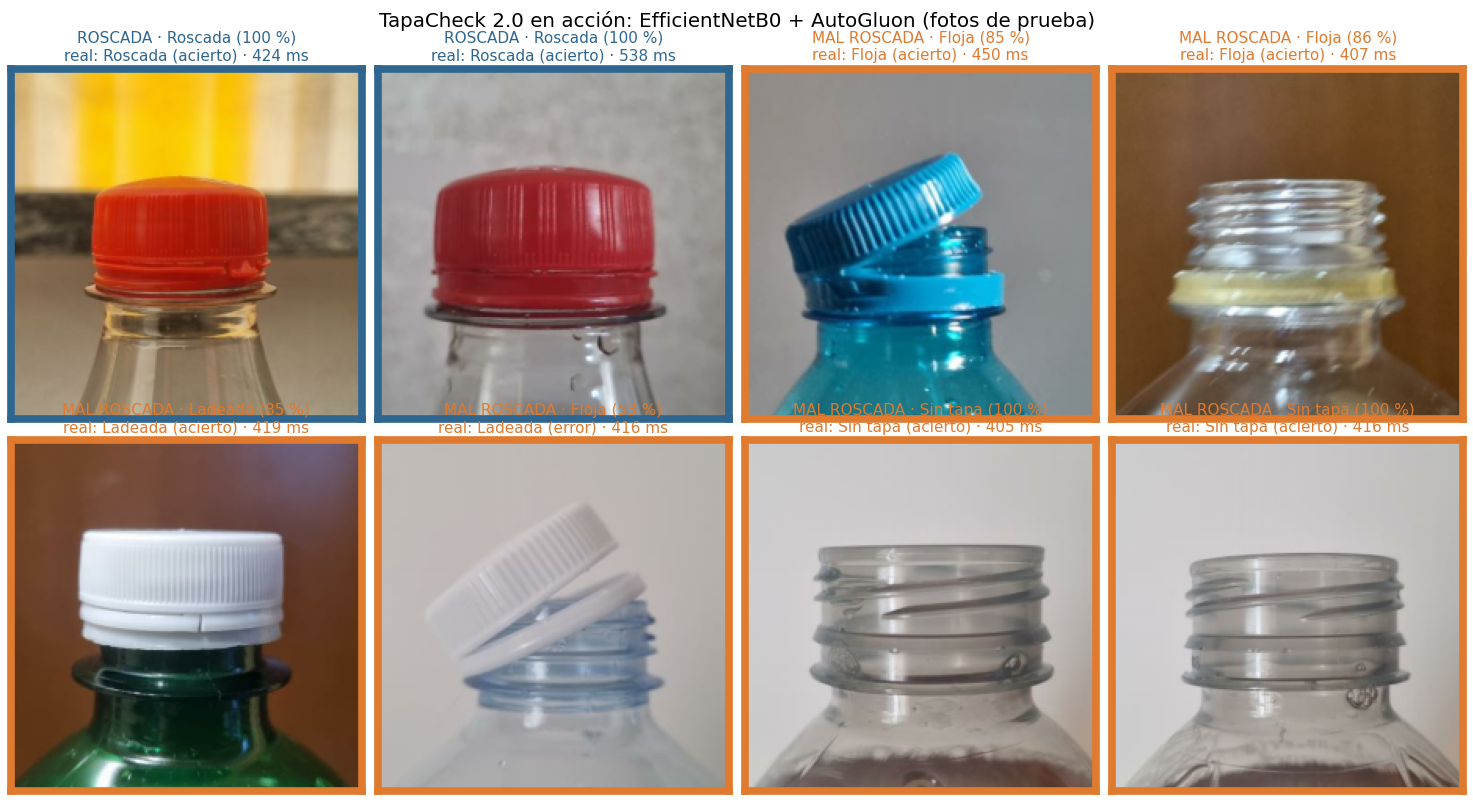

Configuración guardada en modelos\tapacheck_e4.json


In [13]:
rng = np.random.default_rng(7)
elegidas = [i for estado in ESTADOS for i in rng.choice(np.where(info_test['estado'] == estado)[0], 2, replace=False)]
fig, axes = plt.subplots(2, 4, figsize=(13.5, 7.4))
for ax, i in zip(axes.ravel(), elegidas):
    ruta = info_test['ruta'][i]
    estado, veredicto, probabilidades, ms = inspeccionar(ruta)
    acierto = estado == info_test['estado'][i]
    ax.imshow(cargar_y_recortar(ruta).numpy().astype(np.uint8))
    ax.set_xticks([]); ax.set_yticks([])
    color = '#2F6690' if veredicto == 'ROSCADA' else '#E07A2E'
    for borde in ax.spines.values():
        borde.set_color(color); borde.set_linewidth(5)
    ax.set_title(f"{veredicto} · {estado} ({100 * probabilidades[estado]:.0f} %)\n"
                 f"real: {info_test['estado'][i]} ({'acierto' if acierto else 'error'}) · {ms:.0f} ms", fontsize=10, color=color)
plt.suptitle(f"TapaCheck 2.0 en acción: {red_elegida} + AutoGluon (fotos de prueba)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "e4_demo.png"), bbox_inches='tight')
plt.show()

# Configuración que usa demo_tiempo_real.py
config = {'red': red_elegida, 'tamano': list(TAMANO_CNN), 'roi': ROI, 'estados': ESTADOS, 'clases': CLASES,
          'columnas': len(columnas), 'autogluon': ruta_despliegue, 'modelo_autogluon': predictor.model_best,
          'nombres': nombres, 'mapa_estados': MAPA_ESTADOS}
with open(os.path.join(CARPETA_MODELOS, 'tapacheck_e4.json'), 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print(f"Configuración guardada en {os.path.join(CARPETA_MODELOS, 'tapacheck_e4.json')}")

## 10. Conclusiones

1. **La adaptación funciona.** Una red preentrenada en ImageNet, congelada y sin entrenar ni una capa, describe la tapa mejor que HOG, LBP y GLCM de la Entrega 3. Con AutoGluon como cabeza de decisión, el sistema detecta **247 de 249** tapas mal roscadas (antes 227) y **no rechaza ninguna** de las 606 botellas bien tapadas (antes 6).
2. **El mayor salto está en la falla más difícil.** Las tapas ladeadas pasan de 75,7 % a 97,3 % de veredictos correctos. Era el punto débil de los descriptores clásicos, que miran bordes y texturas locales; la red reconoce la forma completa de la tapa sobre el cuello.
3. **También generaliza mejor a días nunca vistos:** detecta el 88,7 % de las tapas mal roscadas (antes 77,4 %) y rechaza el 3,9 % de las buenas (antes 6,3 %). Sigue siendo la principal limitación: con fotos de otros días, botellas o luces, el sistema pierde precisión. Antes de instalarlo en una planta hay que sumar fotos de esa línea.
4. **En el leaderboard ganan los modelos simples sobre el embedding.** La regresión logística y las redes pequeñas superan a los árboles por más de 0,05 de F1, y el ensamble ponderado que los combina queda primero en validación.
5. **Cumple el tiempo real, pero pesa más.** El sistema completo tarda unos 0,4 s por botella en el CPU de un portátil, dentro del ciclo de 1,5 s de la línea; el de la Entrega 3 tarda unos 25 ms. Con el ensamble rápido, la parte de AutoGluon bajaría de casi 0,4 s a unos 20 ms, perdiendo 0,004 de F1 en validación. Reducir ese costo sin perder precisión es el objetivo de la Entrega 5: destilación de conocimiento y estudio de hardware.
6. **Para la embotelladora,** con los mismos supuestos de la Entrega 3, el costo mensual de los errores baja de unos $10,2 millones (Entrega 3) y $16,9 millones (inspección manual) a cerca de $0,5 millones.